# 04 · Econometrics: Granger causality, impulse response, rockets and feathers

Training sample only (May 2000 – June 2025). Crude enters as Brent averaged over the **previous** Mon–Fri, so the "same-week" crude term is already known on the Monday the pump price is collected.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from common import *
import plots; plots.setup()
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
df = load_weekly()
import statsmodels.api as sm
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import coint
train = df[df.split == "train"]
out = {}

## VAR on weekly log changes, Granger causality, response to a 10% Brent shock

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)


lags (AIC): 10
Brent -> CA gas: F=6.29, p=1.343e-09 | CA gas -> Brent: F=1.32, p=0.213
10% Brent shock -> CA gas: 5.34% after 4 wks, 6.46% after 12, 5.93% after 26


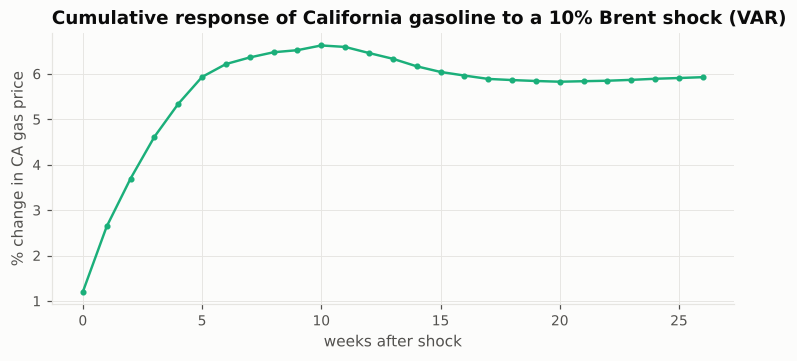

In [2]:
vd = train[["dlog_brent", "dlog_ca_gas"]].dropna()
var = VAR(vd).fit(maxlags=12, ic="aic")
g1 = var.test_causality("dlog_ca_gas", ["dlog_brent"], kind="f")
g2 = var.test_causality("dlog_brent", ["dlog_ca_gas"], kind="f")
oi = var.irf(26).orth_irfs                         # Cholesky, Brent ordered first
cum = np.cumsum(oi[:, 1, 0]) / oi[0, 0, 0] * 0.10  # cumulative % response to a 10% Brent shock
out.update(var_lags=int(var.k_ar), granger_brent_to_gas_F=float(g1.test_statistic), granger_brent_to_gas_p=float(g1.pvalue),
           granger_gas_to_brent_F=float(g2.test_statistic), granger_gas_to_brent_p=float(g2.pvalue),
           irf10_w4=float(cum[4]), irf10_w12=float(cum[12]), irf10_w26=float(cum[26]))
print(f"lags (AIC): {var.k_ar}")
print(f"Brent -> CA gas: F={g1.test_statistic:.2f}, p={g1.pvalue:.4g} | CA gas -> Brent: F={g2.test_statistic:.2f}, p={g2.pvalue:.3f}")
print(f"10% Brent shock -> CA gas: {cum[4]:.2%} after 4 wks, {cum[12]:.2%} after 12, {cum[26]:.2%} after 26")
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(range(27), cum * 100, color=plots.SERIES["brent"], marker="o", ms=3)
ax.set_xlabel("weeks after shock"); ax.set_ylabel("% change in CA gas price")
ax.set_title("Cumulative response of California gasoline to a 10% Brent shock (VAR)")
plots.save(fig, FIG_DIR / "fig07_irf.png"); fig

## Rockets and feathers: asymmetric error-correction model

$$\Delta P_t = \alpha + \sum_{i=0}^{4} \beta_i^{+} \Delta C_{t-i}^{+} + \sum_{i=0}^{4} \beta_i^{-} \Delta C_{t-i}^{-} + \gamma\, ECT_{t-1} + \varepsilon_t$$

P = California price (USD/gal), C = Brent in USD/gal (÷42). HAC standard errors (4 lags).

**Two corrections versus a plain Engle–Granger setup**
1. *Cointegration.* California's premium over crude trends up for 25 years, so P and C are **not** cointegrated around a constant; they are around a linear trend. The long-run regression therefore includes a trend.
2. *What "faster" means.* "Prices rise faster than they fall" is about **speed**, not total pass-through. We test (a) total pass-through Σβ⁺ = Σβ⁻, (b) the first week β₀⁺ = β₀⁻, (c) the first two weeks.

In [3]:
P, C = train["ca_gas"], train["brent"] / 42
ct = {"constant only": coint(P, C, trend="c")[1], "constant + trend": coint(P, C, trend="ct")[1]}
print("Engle-Granger cointegration p-values:", {k: round(v, 3) for k, v in ct.items()})

def ecm_fit(with_trend):
    X = pd.DataFrame({"C": C}, index=C.index)
    if with_trend:
        X["trend"] = np.arange(len(C))
    lr = sm.OLS(P, sm.add_constant(X)).fit()
    dC = C.diff()
    d = pd.DataFrame({"dP": P.diff(), "ect_l1": lr.resid.shift(1)})
    for i in range(5):
        d[f"up_l{i}"] = dC.clip(lower=0).shift(i)
        d[f"down_l{i}"] = dC.clip(upper=0).shift(i)
    d = d.dropna()
    r = sm.OLS(d["dP"], sm.add_constant(d.drop(columns="dP"))).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
    return lr, r

def wald(r, ups, downs):
    names = list(r.params.index); R = np.zeros(len(names))
    for v in ups: R[names.index(v)] = 1
    for v in downs: R[names.index(v)] = -1
    w = r.wald_test(R.reshape(1, -1), scalar=True)
    return r.params[ups].sum(), r.params[downs].sum(), float(w.pvalue)

rows = []
for label, tr in [("no trend (plain Engle-Granger)", False), ("with trend (recommended)", True)]:
    lr, r = ecm_fit(tr)
    for test, k in [("total, weeks 0-4", 5), ("first week", 1), ("first two weeks", 2)]:
        up, dn, p = wald(r, [f"up_l{i}" for i in range(k)], [f"down_l{i}" for i in range(k)])
        rows.append({"long-run spec": label, "test": test, "pass-through up": up, "pass-through down": dn, "Wald p": p,
                     "theta": lr.params["C"], "ECT coef": r.params["ect_l1"], "ECT p": r.pvalues["ect_l1"]})
rf = pd.DataFrame(rows).round(3)
rf.to_csv(RES_DIR / "rockets_feathers.csv", index=False)
rf

Engle-Granger cointegration p-values: {'constant only': 0.891, 'constant + trend': 0.001}


,long-run spec,test,pass-through up,pass-through down,Wald p,theta,ECT coef,ECT p
0,no trend (plain Engle-Granger),"total, weeks 0-4",1.080,1.037,0.796,1.210,-0.005,0.390
1,no trend (plain Engle-Granger),first week,0.486,0.250,0.071,1.210,-0.005,0.390
2,no trend (plain Engle-Granger),first two weeks,0.794,0.528,0.115,1.210,-0.005,0.390
3,with trend (recommended),"total, weeks 0-4",1.097,1.007,0.593,0.874,-0.023,0.073
4,with trend (recommended),first week,0.489,0.245,0.064,0.874,-0.023,0.073
5,with trend (recommended),first two weeks,0.794,0.509,0.096,0.874,-0.023,0.073


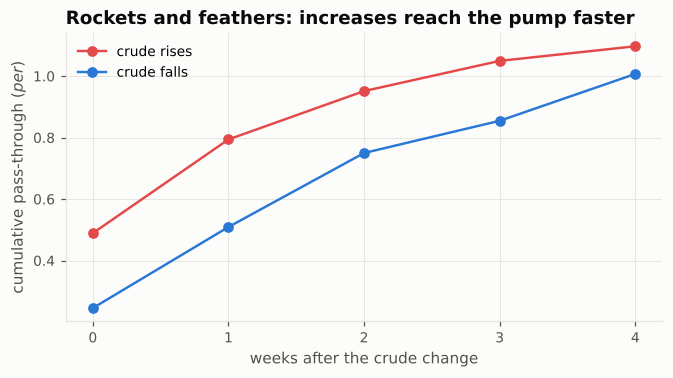

In [4]:
lr, r = ecm_fit(True)
up = np.cumsum([r.params[f"up_l{i}"] for i in range(5)]); dn = np.cumsum([r.params[f"down_l{i}"] for i in range(5)])
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(range(5), up, marker="o", color="#e34948", label="crude rises")
ax.plot(range(5), dn, marker="o", color="#2a78d6", label="crude falls")
ax.set_xticks(range(5)); ax.set_xlabel("weeks after the crude change"); ax.set_ylabel("cumulative pass-through ($ per $)")
ax.set_title("Rockets and feathers: increases reach the pump faster"); ax.legend()
plots.save(fig, FIG_DIR / "fig08_rockets_feathers.png")
out.update(coint_p_const=float(ct["constant only"]), coint_p_trend=float(ct["constant + trend"]))
import json; json.dump(out, open(RES_DIR / "econometrics.json", "w"), indent=1)
fig

**Reading:** total pass-through is about the same for increases and decreases (≈ $1.05–1.10 per $1 of crude, p ≈ 0.6–0.8). The difference is timing: in the first week about half of a crude increase reaches the pump versus a quarter of a decrease (p ≈ 0.06–0.07); after two weeks ≈ 0.79 vs ≈ 0.51 (p ≈ 0.10). Evidence for "rockets and feathers" in speed is therefore weak-to-moderate (10% level), not absent.